# U5-L2：语音合成

**课程目标**

1. 能说明语音合成（TTS）的工作过程：输入一段文字，输出一段能交给扬声器播放的音频数据。
2. 能比较两种让机器人发声的做法（自己构造声音数据，使用 TTS 模型合成），并说出两者的差别。
3. 能区分同步调用与异步调用，并说明SDK的 `synthesize()` 与 `robot.play_sound()` 如何返回句柄、怎样等待结果或播放完成。


## 一、本课要解决的问题

上节课将语音转成了文字。要让机器人说出一段已知的文字，还需要生成对应的声音，再交给扬声器播放。

本课先用程序构造提示音，观察声音数据怎样影响听感；再调用语音合成接口，让机器人用指定音色说出一段文字。


## 二、文字怎么变成声音

机器人说话要分两步走：先把文字变成声音，再把声音送出去。

### 2.1 扬声器播放的原理

扬声器发声的原理：让它的振膜按某个规律来回震动，这个规律就是一段采样数据。

扬声器可以播放上节课使用的PCM采样数据；数据同样需要注明采样率、声道数和采样格式。麦克风是把已有的振动采集下来变成采样点，扬声器可以理解为要把采样点变回振动。把一串采样点按顺序连起来，就是这段声音的**波形**。


### 2.2 声音的合成

在探讨如何根据文字合成语音之前，我们先来看一下如何合成一段声音。

语音一般是指人类说话的声音，它是声音的一个特例。而声音更广泛，噪音、音乐、动物的鸣叫、人类的语音都属于声音。

上节课里，`play_stream()` 输入的是 `record_stream()` 输出的声音块；这个声音块是麦克风基于某个特定采样规律的采样数据。

如果我们可以模仿采样规律“创造”采样数据，再把这段数据输入 `play_stream()` ，声音就放出来了。

下面，模拟一段最简单的波形试试：让电压按正弦规律来回变化。每秒 440 个来回，就是音乐里那个标准音 A。

本课附件构造的是单声道 `S16LE PCM`，每个采样数值占2字节，因此数据量为“时长 × 采样率 × 1 × 2”。上节课K1采音用三声道；本次合成提示音只生成一路数据，播放流也设为单声道。声道数要与实际数据一致。


**STEP 01：** 连接机器人，查看音量

In [1]:
from boosteros.robots.booster import BoosterRobot

robot = BoosterRobot()

print("已连接：", robot.robot_info.model, robot.robot_info.serial_number)
robot.audio_manager.set_system_volume(0.5)
print("当前音量：", robot.audio_manager.get_system_volume())

[Booster OS] [boosteros.sdk] [INFO] SDK Channel initialized on default
[Booster OS] [boosteros.sdk] [INFO] Starting Booster SDK Local Adapter (mode=local, network_interface=default, virtual_robot_name=default).
[Booster OS] [boosteros.sdk] [INFO] Booster SDK Local Adapter started (mode=local, network_interface=default).


Network interface not specified. Will use environment variable (FASTRTPS_DEFAULT_PROFILES_FILE).
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024


[Booster OS] [boosteros.robot] [INFO] Fetching camera configuration from API...
[Booster OS] [boosteros.robot] [INFO] Using cameras ['head'] from API, default camera is 'head'.
[Booster OS] [boosteros.BoosterHandGuidingManager] [INFO] BoosterHandGuidingManager initialized with default_record_file=/opt/booster/Gait/bin/joint_position.txt, record_archive_dir=~/.boosteros/hand_guiding
[Booster OS] [boosteros.ros] [INFO] [/boosteros_ros2_adapter_dba0741f] Booster ROS 2 Adapter initialized. Cameras: head(rgb=/boostercamera/head/rgb, depth=/boostercamera/head/depth). Default camera: head.
[Booster OS] [boosteros.ros] [INFO] [/boosteros_ros2_adapter_dba0741f] Booster ROS 2 Adapter started with 4 threads.
[Booster OS] [boosteros.robot] [INFO] Initializing audio manager & speech runtime...


ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024


RPC request timed out. api_id = 0, uuid = ca797111-deb4-42aa-a95f-31a370ac2d67, timeout_ms = 5000


ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024


[Booster OS] [boosteros.BoosterAudioManager] [INFO] _BoosterAudioRuntime initialized
[Booster OS] [boosteros.BoosterAudioManager] [INFO] BoosterAudioManager initialized
[Booster OS] [boosteros.BoosterSpeechRuntime] [INFO] Booster speech runtime initialized for robot_name=''
[Booster OS] [boosteros.robot] [INFO] Booster OS resources initialized.


ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
已连接： Booster K1 01022026030137
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
当前音量： 0.5


**STEP 02：** 初体验：造一段“声音”并播放

<font color="red">提示：请将本课Notebook与附件 sound_lab.py、fonts/ 文件夹放在同一目录，保持字体文件的位置。这一格会响约1.5秒提示音，音量先调低。</font>


In [2]:
from sound_lab import synthesize_tone, play_sound, plot_waves  # 这不是BoosterOS SDK的方法，而是本课我们为学习特别封装的

freq_1 = 440       # 声波频率：440 Hz，即标准音高 A4
duration_1 = 1.5   # 持续时间：决定这声响多久：1.5 秒

# 1. 合成声音数据
pcm_sound1 = synthesize_tone(freq=freq_1, duration=duration_1, wave_type="sine")

# 2. 发送给机器人扬声器播放
print(f"正在播放：{freq_1} Hz 标准基准音...")
play_sound(robot, pcm_sound1)  # 本课专用
print("播放完毕！")

正在播放：440 Hz 标准基准音...
ChannelSubscriber::InitChannel: setting reliability: 0, queue_capacity: 64
ChannelSubscriber::InitChannel: setting reliability: 0, queue_capacity: 64
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024


RPC request timed out. api_id = 0, uuid = 42d779a8-4d21-4af6-ad0d-3f33807b9f88, timeout_ms = 1000
RPC request timed out. api_id = 0, uuid = e55361e2-f3cc-4e14-adfb-3c2f6e475f4b, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 19ba555d-6883-41f4-87e2-e84a4d826d4d, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 6cff13b0-41e4-418a-9715-a3e4fca7656b, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = be1e5fc0-6293-471f-b4bd-873dcfe6ac14, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = cd15fde2-138f-4395-a670-e9d34154220a, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 8761a706-eb66-476e-8f5d-6f1c51c28ea6, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 2e42b5ab-1387-4e7a-8fc8-34307120268e, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 3b8d169f-012d-4b73-99ec-3e917f8cc9be, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = c6e2fb08-9cd7-44b9-8f46-3827cf2e1f82, timeout_ms = 10
RPC request timed out. api_id = 0, uui

播放完毕！


RPC request timed out. api_id = 0, uuid = 13a9b332-ec63-4151-83ad-cc6377398dc4, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = d29b418c-3f0a-46de-af2a-220a490b6d65, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = e5729ebb-5e26-462c-98e7-16dff31a3c32, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 9ffb0d15-bd40-4c28-a851-c272424eed45, timeout_ms = 10


**知识总结：本实验使用的声音参数**

- **采样率**：每个声道每秒记录多少个数值。附件默认使用16000 Hz。
- **声波频率**：声音每秒振动多少次，影响音调高低。标准音A4的频率为440 Hz。
- **持续时间**：这段声音有多长，单位是秒。

采样率和声波频率都用Hz表示，但数的对象不同：一个数采样次数，一个数振动次数。这里每秒取16000个采样数值，用它们描述每秒振动440次的正弦波，生成约1.5秒的提示音。


**STEP 03：** 挑战：构造你的专属声音

现在轮到你来尝试了！分别试着调整下面的参数：
1. 将频率调到 **880 Hz**（翻倍），听听音调有什么变化？
2. 将频率降低到 **220 Hz**（减半），声音是变得尖锐还是低沉？
3. 修改时长 `duration`，让提示音变得短促（例如 0.3 秒），模拟门禁打卡的声音。

In [3]:
# 请尝试修改这里的数值：
freq_2 = 880       # 提示：可以尝试 220, 523(高音Do), 880
duration_2 = 0.5   # 提示：尝试改成 0.3 或 2.0

pcm_sound2 = synthesize_tone(freq=freq_2, duration=duration_2, wave_type="sine")

print(f"正在播放自定义声音：{freq_2} Hz, {duration_2} 秒...")
play_sound(robot, pcm_sound2)
print("播放完毕！")

正在播放自定义声音：880 Hz, 0.5 秒...


RPC request timed out. api_id = 0, uuid = d45345f6-e8fa-4c18-93a2-2f97bbfe6dba, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 5cb6f5ec-804b-4b4e-9b69-6a758d949985, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 14fb929f-4632-44fd-89b7-2c1a1de690df, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = d6adfeee-03d7-4074-bfc6-092be6a084cc, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 487cb72c-a2b4-4949-ab73-71d91e672b2d, timeout_ms = 10


播放完毕！


RPC request timed out. api_id = 0, uuid = 41549a2c-2102-4c1c-87c2-3075605b52a0, timeout_ms = 10


**STEP 04：** 比较声音的波形

运行下面的程序，观察两种设置在最初10毫秒内的波形。在相同时间内，哪一种设置的波峰更多？将图上的变化与刚才听到的音调高低对应起来。


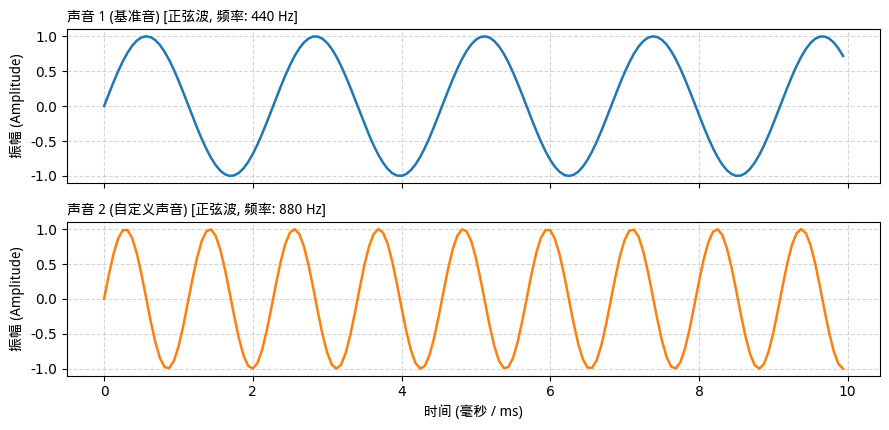

In [4]:
# 将前两次生成的声音配置传入可视化函数
plot_waves([
    {"name": "声音 1 (基准音)", "freq": freq_1, "wave_type": "sine"},
    {"name": "声音 2 (自定义声音)", "freq": freq_2, "wave_type": "sine"},
], window_ms=10.0)

**STEP 05：** 比较不同波形的音色

频率相同的钢琴、笛子和蜂鸣器，听起来仍有差别，这与**音色**有关。声音中有哪些频率成分，各成分有多强，以及声音如何逐渐增强、衰减，都会影响音色。这里不展开计算，先试听几种合成方式：

- `sine`（正弦波）：较纯净的单音。
- `square`（方波）：听感接近一些早期电子游戏的提示音。
- `sawtooth`（锯齿波）：听起来较明亮、尖锐。
- `bell`（钟琴声）：多个频率成分叠加后逐渐衰减，模拟敲击后的声音。

下面先画波形示意，再试听。图是依据配置重新计算的示意，不是从本次播放数据中抽出的测量图；尤其 `bell` 的绘图与试听采用不同的简化表达式，用于观察叠加与衰减的特点。


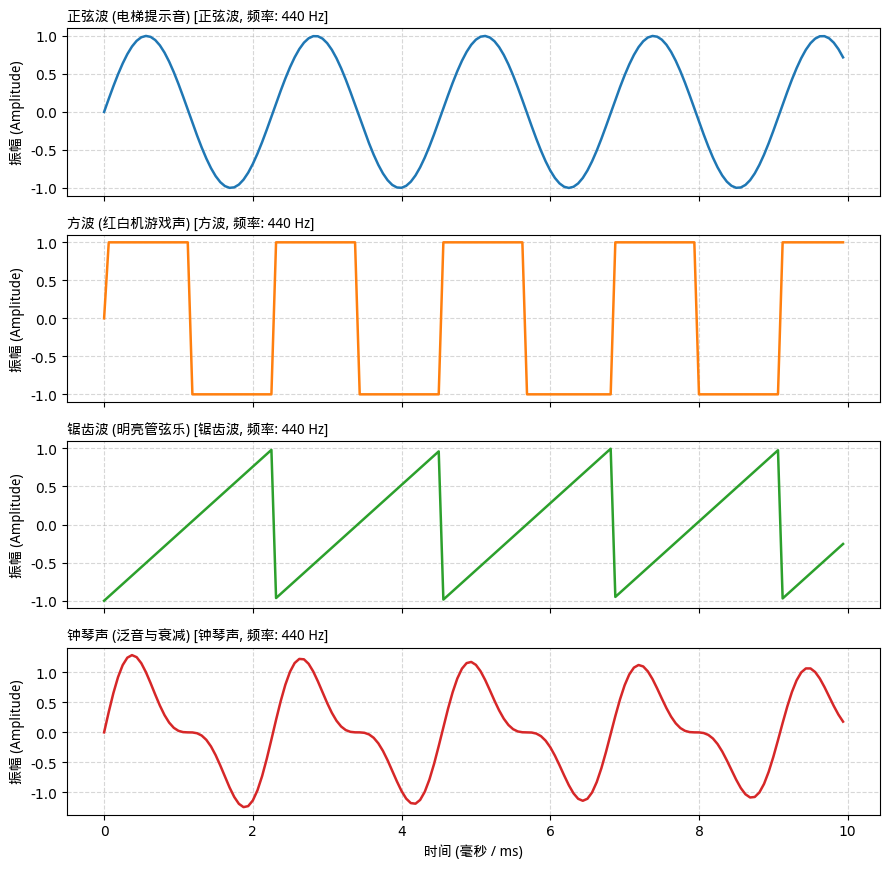

正在播放：正弦波 (电梯提示音)...


RPC request timed out. api_id = 0, uuid = 3772117c-9b59-444a-89f3-ce47b6e9ebfd, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 2d886360-fdee-448f-b3f3-e5cea9962ec8, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 802b3816-01c2-43a2-975e-d6deae54d5ba, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 57fb800e-2b32-4e66-8e3e-d65428ec5250, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 8fbb8ea9-dfb8-47c8-a08a-e4ac5fca35eb, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = a58de192-03c8-4420-9157-64486c4ef155, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 2e77f6fa-5827-4c77-8735-dd3b8ae12785, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 99a5b899-9c96-4d03-bd14-1c9c969d582c, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 203cc074-6de5-4f73-a9b7-616968563313, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = b6bb0a5e-6b52-4657-83f5-e998cbda53ae, timeout_ms = 10
RPC request timed out. api_id = 0, uuid 

正在播放：方波 (红白机游戏声)...


RPC request timed out. api_id = 0, uuid = 5fced802-2bde-47b6-bf29-8469e4bb1097, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 409548e7-8fd9-420c-b01c-ca9681b1533f, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 63aedc96-3813-4368-87ae-9c8413849b45, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = eccca241-64eb-4f0f-a338-818b1b11be19, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = e5a6c1d6-b598-4e6a-af2e-5f89602b3043, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 836799a9-9c3c-410e-b707-d13ae17df08e, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 9a75d66d-b10c-471e-a75d-e48c8f496e81, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 70648435-036d-4d1c-8789-164bf344b3ef, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 48ac1931-54c6-4c1c-b776-233971b08ae1, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = f6f2dd0e-c23d-4693-bf19-5d87a0e2481a, timeout_ms = 10


正在播放：锯齿波 (明亮管弦乐)...


RPC request timed out. api_id = 0, uuid = 0a3c3f26-b79d-44be-8cbf-a6f1537b0f70, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = c69bffb5-0529-413d-9b55-477c82910b01, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 825f4c1b-9d7d-41bf-8d3d-43cbd6c45fd4, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 0fa90077-64e3-465b-9220-792719c4e485, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = ff593e13-0051-4699-92c2-39afa3cd0352, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 921dff02-9f42-4752-9674-ba0e7cd64c12, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = f7530e64-e51b-4600-98ff-e27258bec69c, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 572417ca-3451-4490-9e61-5b63cf684c74, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 4a2ef872-f27f-4f81-91a4-e9f054864c23, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 3ca16303-b9f4-42af-8a6e-4ed41fe861bf, timeout_ms = 10
RPC request timed out. api_id = 0, uuid 

正在播放：钟琴声 (泛音与衰减)...


RPC request timed out. api_id = 0, uuid = e704587a-87b9-454a-b48b-c3d03a2ae848, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 1e5f0c90-cdb1-495f-8a3d-d18f33981265, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 272b4242-5b96-4837-b3bd-925dd8fe12a9, timeout_ms = 10


全部播放完毕！


RPC request timed out. api_id = 0, uuid = 13c6071e-65db-41f8-a46b-ddc7684b53f5, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 880f5ac8-30af-4ff8-8383-e04b7e66a185, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = e38aa484-9a43-457a-bd96-63642bd50d15, timeout_ms = 10


In [5]:
# 1. 绘制4种波形的示意图（不是本次播放数据的逐点测量）
wave_types = ["sine", "square", "sawtooth", "bell"]
compare_configs = [
    {"name": "正弦波 (电梯提示音)", "freq": 440, "wave_type": "sine"},
    {"name": "方波 (红白机游戏声)", "freq": 440, "wave_type": "square"},
    {"name": "锯齿波 (明亮管弦乐)", "freq": 440, "wave_type": "sawtooth"},
    {"name": "钟琴声 (泛音与衰减)", "freq": 440, "wave_type": "bell"},
]
plot_waves(compare_configs, window_ms=10.0)

# 2. 依次播放这 4 种音色，闭上眼睛感受差异
for item in compare_configs:
    print(f"正在播放：{item['name']}...")
    audio_data = synthesize_tone(freq=item["freq"], duration=1.2, wave_type=item["wave_type"])
    play_sound(robot, audio_data)
print("全部播放完毕！")


### 2.3 语音合成（TTS）

人说话：大脑想好要说的意思，声带振动，口腔和鼻腔把振动捏成一个个音。人说的话本质上也是声音，但它是符合特定规律的声音，这个特定的规律就是人类文字的读音。

因此，机器人模仿人说话的本质是：把一段文字输入给一个模型，这个模型把它变成“声音”，并由扬声器播放出来。把文字变为声音这一步叫**语音合成**，英文缩写 TTS。

模型怎么把文字变成声音，属于另一个领域，这门课不展开。本课只关心：**给它什么（输入）**（一段文字）、**反馈什么（输出）**（一段能放的声音）。

在 `BoosterOS SDK` 的 `Speech` 中有一个 `synthesize()` 接口，它提供将文本合成为语音的功能。用法如下：

- `text`：`str`类型，待合成的文本，最大`300`字符；
- `voice`：`str`类型，合成音色ID，默认为`"default"`；
- `speed`：`float`类型，合成语速倍率，默认值为`1.0`。

`synthesize()` 调用后的返回对象为 `TaskHandle[AudioData]` ，调用  `handle.result()` 等待合成完成并获取音频数据。

**STEP 06：** 对一段文字进行语音合成


In [8]:
from boosteros.brain import Speech
import os

speech = Speech(robot)  # robot在前面已经创建

# 异步调用，立即返回 TaskHandle
handle = speech.synthesize("今天天气真好，欢迎使用 Booster 机器人。")
audio = handle.result()  # 阻塞等待合成完成
print(f"生成音频时长：{audio.duration.seconds:.2f} 秒")

# 将合成完成的声音保存下来
save_path = os.path.join(os.getcwd(), "booster_synthesize.wav")
audio.save(save_path)


[Booster OS] [boosteros.speech.booster] [INFO] Resampling TTS output from 24000Hz to 16000Hz for consistency


合成完成: 3.18s


**STEP 07：** 播放合成的声音


In [9]:
playback = robot.play_sound(save_path)
playback_status = playback.wait()
if playback_status == "SUCCEEDED":
    print("播放完成")
else:
    print("播放未成功，状态：", playback_status, "；错误：", playback.error)


播放结束


### 2.4 音色

语音合成的方法中提到了“音色”，对于人说话来说，每个人的声音听起来都不一样，这其实就是**音色**。

目前同一个**语音合成模型**一般可以合成不同的**音色**。

在 BoosterOS SDK 里调用 `list_voices()` 可以获取可用的音色列表。返回值中有一个 `id` 字段，是不同音色的唯一编码。

在使用语音合成功能想要替换音色时，只需要修改一下对应的字符串就可以了，真实项目里客户说换个更「沉稳」的嗓音，改的就是这里。

**STEP 08：** 查看机器人的音色清单

<font color="red">提示：</font>
1. 下一格只看清单，不会出声。
2. 程序的输出中有一个重要的参数是 `capabilities`，它代表支持的语音能力列表，取值如下：
    - `"chat"`，可用于 `Speech.chat()` 的语音对话音色
    - `"synthesize"`，可用于 `Speech.synthesize()` 的语音合成音色


In [10]:
voices = speech.list_voices()  # speech在前面已经创建
print("可用音色个数：", len(voices))
for v in voices:
    print("  ", v)

可用音色个数： 4
   {'id': 'warm_ahu', 'name': '男声-温暖阿虎', 'gender': 'male', 'capabilities': ['chat']}
   {'id': 'bright_sisi', 'name': '女声-爽快思思', 'gender': 'female', 'capabilities': ['chat']}
   {'id': 'vv_uranus', 'name': '女声-vivi', 'gender': 'female', 'capabilities': ['synthesize']}
   {'id': 'ruya_yichen', 'name': '男声-儒雅逸辰', 'gender': 'male', 'capabilities': ['synthesize']}


**STEP 09：** 换一个音色

<font color="red">提示：</font>使用`capabilities`为`"synthesize"`的ID。


In [ ]:
# 在 STEP 08 选择一个音色，把音色 ID 记录下来
VOICE_1 = "填音色 ID"  # vv_uranus 或 ruya_yichen

Text = "请用一句话介绍一下这个展厅。"

# 异步调用，立即返回 TaskHandle
handle = speech.synthesize(Text, voice=VOICE_1)
audio = handle.result()  # 阻塞等待合成完成
print(f"生成音频时长：{audio.duration.seconds:.2f} 秒")

# 播放合成声音
playback = robot.play_sound(audio)
playback_status = playback.wait()
if playback_status == "SUCCEEDED":
    print("播放完成")
else:
    print("播放未成功，状态：", playback_status, "；错误：", playback.error)


[Booster OS] [boosteros.speech.booster] [ERROR] Booster synthesize task failed
Traceback (most recent call last):
  File "/home/booster/.local/lib/python3.10/site-packages/boosteros/brain/speech/_providers/booster/task_handles.py", line 101, in _run
    audio = self._synthesize_fn()
  File "/home/booster/.local/lib/python3.10/site-packages/boosteros/brain/speech/_providers/booster/provider.py", line 83, in _sync_synthesize
    runtime.lui_client.StartTts(br.LuiTtsConfig(voice_type))
RuntimeError: API call failed, code = 409


RuntimeError: API call failed, code = 409

## 三、指令的两类工作模式：同步与异步

通过程序控制机器人，靠的是一条条指令。指令在被调用时，通常有两类常见的工作模式：同步与异步。

### 3.1 同步调用

同步调用会在当前代码里等待，直到本次调用返回，才执行下一行。例如查询音量、列出音色，都要先取得返回值才能继续。

“同步”描述的是调用和返回的关系，并不保证很快。如果服务或网络响应较慢，同步调用也会等待较久。


### 3.2 异步调用

调用 `synthesize()` 时，合成工作可能还没有完成，函数就先返回一个**任务句柄**。可以把句柄想成办理业务的取号单：凭它查看任务是否结束，或取得结果。

本课常用的句柄操作：

| 操作 | 含义 |
|---|---|
| `status` | 当前任务状态，例如等待、运行、成功、失败或取消；不显示内部识别、推理、合成的步骤 |
| `done()` | 是否已进入成功、失败或取消这三种终态之一 |
| `running()` | 是否处于 `RUNNING`；为假还可能在等待或取消中 |
| `wait(timeout=...)` | 等待任务结束；超时返回当前状态，任务可能仍在运行 |
| `result()` | 等待有具体结果的任务，成功后取得结果；合成任务得到 `AudioData` |
| `cancel()` | 请求取消，返回请求是否成功提交；还需等待并检查是否结束 |

异步接口允许程序在任务执行期间继续做其他事；也可以立即等待。本课先调用 `synthesize()`，再用 `result()` 取得合成音频：

```python
handle = speech.synthesize("欢迎来到实训室。")
audio = handle.result()
```

SDK的 `robot.play_sound(audio)` 也返回句柄；调用 `.wait()` 可以等播放任务结束。两者都是异步接口，后面加等待不会改变接口本身的类型。

本课附件中的 `play_sound(robot, pcm_data)` 是教学封装，内部依次写入声音、`close()`结束输入、`wait()`等待播放；成功后才返回，供我们按顺序试听。它与SDK的 `robot.play_sound()` 名称相似，调用方式和返回行为不同。

`close()`只结束播放流的输入，队列里的声音会继续播放，因此之后仍需要 `wait()`。持续识别或对话则没有预定的结束时长，`wait()`等待的是整个任务结束，不能用来判断用户的一句话是否已经处理完。


## 四、实验：主动提问的智能助手

⚠️ **注意**：本课不让机器人走动，只用到麦克风与扬声器。机器人说完之后场地安静一些，识别效果会更好；音量先调好，中途别改。

这一格把本课两件事串起来：先让机器人合成一句问候说给人听，再听人怎么回答。

**STEP 10：** 主动提问的智能助手

先合成并播放一句提问，成功播放后，再留6秒观察人的语音转写。这里暂不生成回答，也不查询外部信息。取消识别后检查 `done()`；若仍未结束，先处理原任务，再重新运行。


In [23]:
from boosteros.brain import Speech
import time

speech = Speech(robot)

if "task" in globals() and not task.done():
    print("上一项语音任务尚未结束，状态：", task.status)
    print("先运行 task.cancel()，再运行 task.wait(timeout=5.0)，确认 task.done() 为 True 后重试。")
else:
    welcome_msg = "你好，欢迎来到实训室，请问你想了解机器人的哪一项功能？"
    handle = speech.synthesize(welcome_msg)
    audio = handle.result()
    print(f"生成音频时长：{audio.duration.seconds:.2f} 秒")

    playback = robot.play_sound(audio)
    playback_status = playback.wait()
    if playback_status != "SUCCEEDED":
        print("播放未成功，暂不开始识别。状态：", playback_status, "；错误：", playback.error)
    else:
        def on_text(text):
            print("识别到：", text)

        task = speech.recognize_stream(on_result=on_text)
        print("开始识别，请回答刚才的问题")
        try:
            time.sleep(6)  # 观察窗口，不是识别处理耗时
        finally:
            accepted = task.cancel()
            print("取消请求已提交：", accepted)
            task.wait(timeout=5.0)
        print("当前状态：", task.status, "；是否已结束：", task.done())
        if not task.done():
            print("任务尚未结束，保留 task 继续检查，暂不再次运行。")
        elif task.status == "FAILED":
            print("识别失败：", task.error)


[Booster OS] [boosteros.speech.booster] [INFO] Resampling TTS output from 24000Hz to 16000Hz for consistency


合成完成: 4.77s


RPC request timed out. api_id = 0, uuid = 378e4e72-f75b-40f9-9f33-023a702a2035, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = ac575d15-915c-4d69-bcf5-09e5437fb1f9, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 23e82e18-210a-4389-9ac7-56b5e78f3dfc, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 87da8de8-32f6-4d1e-b577-5564a7ac60eb, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 0d3b0744-c848-4c2a-8203-c9bdd0aa8a56, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 643149f2-c340-47fd-b736-4a62cc1ef598, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = f7eb4551-e36a-427f-baeb-5b150e83696a, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = 4acf21ba-e091-48e2-b37e-33af9801c75e, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = f3c60d50-040f-473c-8f43-7e2dd79d2092, timeout_ms = 10
RPC request timed out. api_id = 0, uuid = ff8e4028-e5b8-44b6-8085-9975d00869be, timeout_ms = 10
RPC request timed out. api_id = 0, uuid 

开始识别，请回答刚才的问题
识别到： 北京
识别结束，任务状态： CANCELLED


## 五、观察与记录

### 5.1 不同音色的对照

| 音色 ID | 听感（高/低、快/慢、稳/飘） | 合成出来的时长（秒） |
| :--- | :--- | :--- |
| `default`默认 | 　　　　　　　　　　　　 | 　　　　 |
| ID：　　　　　　 | 　　　　　　　　　　　　 | 　　　　 |

### 5.2 自己造的声音数据

| 项目 | 记录 |
| :--- | :--- |
| 采样率 / 声道数 / 采样格式 | 　　　　 |
| 采样点个数 | 　　　　 |
| 字节数 | 　　　　 |
| 音频时长（秒） | 　　　　 |
| 频率改成 880 之后，听起来变了什么 | 　　　　　　　　　　　　　　　　 |

### 5.3 检查点

- 是否能说清扬声器的原理，它可以播放的是什么、TTS 在中间做了什么。
- 是否能判断一个调用是同步还是异步。
- 是否能区分等待有限任务完成，与请求取消持续任务；是否知道取消后还要确认终态。

### 5.4 思考题

- 自己构造的声音文件和 TTS 合成的语音，有什么共性，为什么最后都能从同一个扬声器播放出来？
- 同一个模型能说出好几种音色，模型在训练的时候做了什么？（提示见「扩展阅读」）
- 目前我们实现了机器人的“听”和“说”，想一想：如果想让机器人有对话功能，还缺少什么过程？


## 六、扩展阅读：音色是怎么造出来的

同一个模型能说出不同的“嗓音”，是因为它的输出可以偏向不同的目标。

早期造音色有两种办法。一种是**拼接**：把一个人念的很多小段录下来，说话时挑合适的段拼起来，段与段接缝处听起来不自然。另一种是**参数法**：把人的声道简化成一组参数，用参数算出声音，声音干净但听起来不像真人。

现在常用的第三种是**神经网络合成**：让模型直接从大量录音里学会「这段文字配这个声音」，连音色也一起学进去。换音色的做法就是拿另一批录音再教一遍，或者让一次训练里同时学很多人的声音，用编号区分——服务再用音色ID标识可选声音；ID本身不一定就是训练时的说话人编号。

这些方法都要生成可播放的声音。在本课的SDK接口中，合成结果统一表示为 `AudioData`，因此换音色后，取结果和播放的程序流程可以保持一致。
